# 解四角分割 ― 用布尔变量把格子和数字绑起来

## 这一章要学什么

四角分割（Shikaku）是把盘面切成一块块矩形的谜题。这一章我们让布尔变量去描述切法，剩下的交给 SAT。

- 每个数字，先把含它的矩形候选全造出来，然后让它恰好选一个
- 每个格子，也从“自己能归到哪个数字名下”里恰好选一个
- 再用蕴含把两头接上：矩形选上了，里头的格子就都归那个数字

有个辅助库 `helper.sat.SATHelper`，CNF 写起来能短不少。

## 规则

1. **必须切成矩形或正方形**
   - 给定的格子，一块一块切成矩形或者正方形。
2. **一个区域只放一个数字**
   - 每个区域里，题目给的数字恰好有一个。
3. **数字就是面积**
   - 那个数字表示的，是它所在区域里有**几个格子**。
4. **所有格子都得用上**
   - 区域之间不重叠，每个格子都落在某个区域里。

谜题初始状态             |  解答
:-------------------------:|:-------------------------:
![](https://upload.wikimedia.org/wikipedia/commons/5/58/Shikaku_start.png) |  ![](https://upload.wikimedia.org/wikipedia/commons/e/ee/Shikaku_end.png)

`````{admonition} 四角分割谜题网站
:class: tip
https://www.puzzle-shikaku.com/

用 `helper.puzzle.extract_shikaku()`，就能从这个网站取到谜题的盘面。打开浏览器的开发者工具，把表示盘面的 `<div>` 标签代码复制下来，再跑一下这个函数，盘面就以数组的形式拿到手了。
`````

## 思路

变量只有两种。

| 变量 | 含义 |
|---|---|
| 矩形变量 | “作为数字 `p` 的矩形，就选这一块” |
| 格子变量 | “格子 `q` 落在数字 `p` 的矩形里” |

约束三条。

1. 每个数字，候选矩形里**恰好一个**为真（这个数字的矩形就此定下）
2. 每个格子，它归谁所有这件事里**恰好一个**为真（所有格子都各进一个区域）
3. 矩形一旦选上，里头的格子就全归那个数字（蕴含）

只靠这三条，区域重叠、“一个区域里塞进两个数字”这些情况就都自动被挡在外面了。

## 代码

`helper.sat.SATHelper` 是个小类，专门用来拼 CNF。

- `next()` … 造一个变量，编号往后顺延
- `next(n)` … 一气造 `n` 个变量，返回编号列表
- `exact_n(vs, n)` … 追加约束：“`vs` 里恰好 `n` 个为真”
- `implies_all(a, vs)` … 对 `vs` 里每个变量 `x` 追加 `a → x`
- `solve()` … 求解，把模型返回来

先备好一个函数，用来造矩形候选：把包含数字格子 `(x, y)`、面积正好是 `area` 的矩形全部列出来。

In [1]:
import numpy as np
from helper.sat import SATHelper
from collections import defaultdict
from itertools import product
from collections import namedtuple

Rectangle = namedtuple("Rectangle", "x y w h")   # x=列, y=行, w=宽, h=高


def mult_pair(n):
    """返回所有满足 n = w * h 的 (w, h)"""
    n = int(n)
    for w in range(1, n + 1):
        h = n // w
        if w * h == n:
            yield w, h


def generate_rectangle(x, y, area, width, height):
    """返回包含格子 (x, y)、面积为 area 的所有矩形"""
    for w, h in mult_pair(area):
        for i, j in product(range(w), range(h)):
            # 让数字格落在矩形内 (i, j) 的位置
            x2, y2 = int(x) - i, int(y) - j
            if x2 >= 0 and y2 >= 0 and x2 + w <= width and y2 + h <= height:
                yield Rectangle(x2, y2, w, h)


def generate_cell(rect):
    """依次返回矩形包含的格子"""
    x, y, w, h = rect
    for i, j in product(range(w), range(h)):
        yield x + i, y + j

`ShikakuSolver` 造变量的顺序是这样的。

1. 每个数字，每个候选矩形配一个变量（`rect_variables`）
2. 每个格子，“有可能盖住它的数字”各配一个变量（`cell_variables`）

`rect_variables[x, y]` 是 `{变量编号: 矩形}` 这样的字典，`cell_variables[x, y]` 则是 `{数字的位置: 变量编号}`。

In [2]:
class ShikakuSolver:
    def __init__(self, board):
        board = np.array(board)
        height, width = board.shape
        self.height = height
        self.width = width

        sat = SATHelper()

        # 1. 对每个数字造候选矩形
        rect_variables = {}
        for y, x in zip(*np.where(board > 0)):
            x, y = int(x), int(y)
            area = int(board[y, x])
            number_rects = {}
            for rect in generate_rectangle(x, y, area, width, height):
                number_rects[sat.next()] = rect
            rect_variables[x, y] = number_rects

        # 2. 对每个格子收集可能包含它的数字
        cells = defaultdict(set)
        for (x0, y0), number_rects in rect_variables.items():
            for rect in number_rects.values():
                for xc, yc in generate_cell(rect):
                    cells[xc, yc].add((x0, y0))

        # 3. 对每个格子，每个数字造一个变量
        cell_variables = {}
        for cell, numbers in cells.items():
            cell_variables[cell] = dict(zip(numbers, sat.next(len(numbers))))

        self.rect_variables = rect_variables
        self.cell_variables = cell_variables
        self.sat = sat
        self.board = board

    def solve(self):
        sat = self.sat
        rect_variables = self.rect_variables
        cell_variables = self.cell_variables

        # 约束1：每个数字的矩形只有一个
        for rects in rect_variables.values():
            sat.exact_n(rects.keys(), 1)

        # 约束2：每个格子恰好属于一个数字
        for numbers in cell_variables.values():
            sat.exact_n(numbers.values(), 1)

        # 约束3：选了矩形后，里面的格子属于那个数字
        for pos, rects in rect_variables.items():
            for var_rect, rect in rects.items():
                var_cells = [cell_variables[xc, yc][pos] for xc, yc in generate_cell(rect)]
                sat.implies_all(var_rect, var_cells)

        # 求解并取出被选中的矩形
        model = sat.solve()
        if model is None:
            self.sol_rects = []
            return []

        self.solution = model
        self.sol_rects = [rect
                          for rects in rect_variables.values()
                          for var_rect, rect in rects.items()
                          if model[var_rect - 1] > 0]
        return self.sol_rects

把谜题解出来，结果画出来。

In [3]:
puzzle = np.loadtxt("data/shikaku01.txt", dtype=np.int16)
solver = ShikakuSolver(puzzle)
rects = solver.solve()
print(len(rects), "个矩形")

45 个矩形


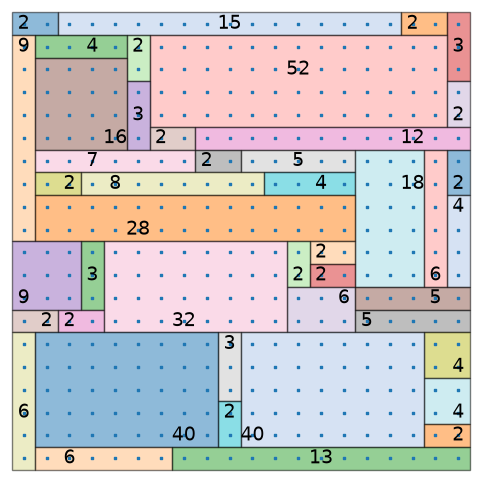

In [4]:
from helper.plot import plot_shikaku_board

plot_shikaku_board(solver.board, rects);

## 看看变量里装了什么

`rect_variables` 装的是“每个数字手上的候选”。挑坐标 `(3, 1)` 上那个数字 4 看看（`solver.rect_variables[3, 1]`）。

In [5]:
solver.rect_variables[3, 1]

{26: Rectangle(x=3, y=1, w=1, h=4),
 27: Rectangle(x=3, y=0, w=1, h=4),
 28: Rectangle(x=3, y=1, w=2, h=2),
 29: Rectangle(x=3, y=0, w=2, h=2),
 30: Rectangle(x=2, y=1, w=2, h=2),
 31: Rectangle(x=2, y=0, w=2, h=2),
 32: Rectangle(x=3, y=1, w=4, h=1),
 33: Rectangle(x=2, y=1, w=4, h=1),
 34: Rectangle(x=1, y=1, w=4, h=1),
 35: Rectangle(x=0, y=1, w=4, h=1)}

包含数字 4 的矩形，面积得正好是 4（1×4, 2×2, 4×1），而且位置不能探出盘面。

从这些里头只挑一个，就是 `exact_n(rects.keys(), 1)`。到底挑了哪个？看模型。

In [6]:
# 从模型里取出 rect_variables[3, 1] 的变量编号
for var, rect in solver.rect_variables[3, 1].items():
    if solver.solution[var - 1] > 0:
        print(var, rect)

34 Rectangle(x=1, y=1, w=4, h=1)


只挑了一个，看得出来。

再看格子那一侧。`cell_variables[2, 1]` 装的是“格子 (2, 1) 归哪个数字的矩形”的候选。

In [7]:
solver.cell_variables[2, 1]

{(0, 1): 1048, (3, 1): 1049, (12, 2): 1050}

这个格子有 3 个数字的矩形可能盖住它。其中只有一个能为真，靠的就是 `exact_n(numbers.values(), 1)`。

In [8]:
for pos, var in solver.cell_variables[2, 1].items():
    print(pos, var, solver.solution[var - 1] > 0)

(0, 1) 1048 False
(3, 1) 1049 True
(12, 2) 1050 False


被选中的那个数字位置，值为 `True`。

## 把两种变量接上

最后一条约束是：“矩形选上了，里头的格子就归那个数字。”

```python
for pos, rects in rect_variables.items():
    for var_rect, rect in rects.items():
        var_cells = [cell_variables[xc, yc][pos] for xc, yc in generate_cell(rect)]
        sat.implies_all(var_rect, var_cells)
```

`implies_all(A, Bs)` 对 `Bs` 里的每个变量 `X` 都追加一条 `A → X`，也就是 `-A | X`。矩形一选定的那一刻，里头所有格子就被钉死成“那个数字的”了。

它和约束 2（每个格子只归一个数字）一配合，矩形之间不重叠这件事就有了保证。

## 更难的题目

谜题网站上最难的那一档，也解得动。

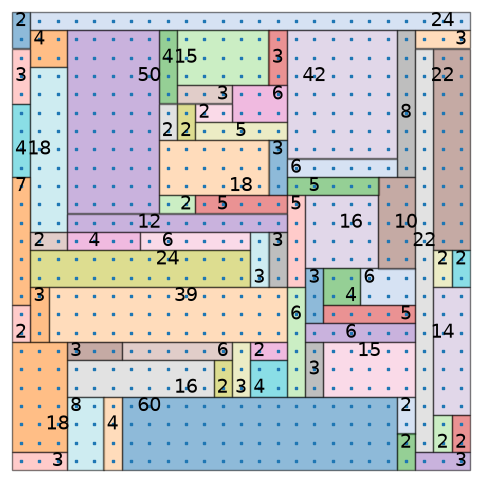

In [9]:
puzzle = np.loadtxt("data/shikaku02.txt", dtype=np.int16)
solver = ShikakuSolver(puzzle)
rects = solver.solve()
plot_shikaku_board(solver.board, rects);

## 验算

解出来的矩形，到底合不合规则，查一遍。

In [10]:
def check_shikaku(board, rects):
    """每个矩形是否只含一个数字、面积与数字一致、所有格子各用一次"""
    height, width = board.shape
    covered = np.zeros_like(board, dtype=int)

    for x, y, w, h in rects:
        numbers = [board[y + j, x + i]
                   for j in range(h) for i in range(w)
                   if board[y + j, x + i] > 0]
        if len(numbers) != 1 or numbers[0] != w * h:
            return False
        covered[y:y+h, x:x+w] += 1

    return bool((covered == 1).all())


print(check_shikaku(solver.board, rects))

True


## SATHelper 是怎么写的

`exact_n()` 和 `implies_all()` 的内部，就这些。都不长，读一遍下来，CNF 该怎么拼就有感觉了。

```python
def exact_n(self, variables, n, extend=True):
    cnfs = []
    variables = [int(v) for v in variables]
    # 禁止 n+1 个同时为真
    for c in combinations(variables, n + 1):
        cnfs.append([-v for v in c])
    # “至少 n 个”… 不能让为假的个数超过 len - n + 1
    for c in combinations(variables, len(variables) - n + 1):
        cnfs.append([v for v in c])
    if extend:
        self.extend(cnfs)
    return cnfs


def implies(self, A, B, extend=True):
    if isinstance(B, int):
        B = [B]
    cnf = [-A] + B          # A → B 就是 (~A | B)
    if extend:
        self.extend([cnf])
    return cnf


def implies_all(self, A, Bs, extend=True):
    return [self.implies(A, B, extend=extend) for B in Bs]
```

`exact_n(vs, 1)` 落到“恰好一个为真”。分两段下手：不许有 `n+1 = 2` 个同时为真；也不许 `len - n + 1 = len` 个（也就是全部）都为假。

## 小结

- 每个数字造一批矩形候选，用 `exact_n(vs, 1)` 让它挑一个
- 每个格子造一批所属候选，同样用 `exact_n(vs, 1)` 挑一个
- 用蕴含接上“选了矩形，里头的格子就归那个数字”，重叠也就自动挡住了
- 有 `helper.sat.SATHelper`，CNF 的组装能写得很短
- 解出来的结果，交给验算代码过一遍